# Viz comparison: real graph against v2 non-private and graph-aim-walks

The same plots as `viz_comparison.ipynb`, for the question of `docs/snap/walks-plan.md`: with privacy set aside, can
a generator that only sees readable tables of random-walk statistics produce graphs whose walks look real? Black is
always the **real** graph. The two synthetic series are both **non-private** (exact statistics of the real graph,
not a DP release): **v2 non-private** (graph-AIM v2, no caps, no noise; `snap/outside/synthetic_v2/`) and
**graph-aim-walks** (`snap/outside/synthetic_walks/`), which starts from v2 and then matches the walk tables.

Sections 1-6 and 8 are the plots of `viz_comparison.ipynb` unchanged. Section 9 shows communities and section 10 the
walk statistics, both **matched** (what the walks generator was fitted to: walks of up to 32 steps) and **held out**
(never matched: walks beyond 32 steps, windows of 64 and 128 steps, Louvain communities). The held-out checks are
the ones that say whether the generator learned the structure or only the tables. Section 11 gives the numbers.
A series whose graph file does not exist yet is skipped (the setup cell says which).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NB = Path.cwd()
EVAL = NB.parent if NB.name == "notebooks" else NB          # snap/eval
SNAP = EVAL.parent
sys.path.insert(0, str(SNAP.parent / "src"))

from graph_aim.eval import viz
from graph_aim.eval.evaluate import align_columns, comparison_table, degrees
from graph_aim.transfer.graph_io import load_attributed_graph
from graph_aim_walks.eval import viz as walks_viz
from graph_aim_walks.eval.metrics import community_metrics, default_spec, walk_metrics, walk_profile

from IPython.display import display

plt.rcParams["figure.dpi"] = 110


def show(fig):
    # display explicitly (works on any backend), then free the figure
    display(fig)
    plt.close(fig)

real = load_attributed_graph(SNAP / "inside" / "data" / "processed" / "attributed_graph.npz")
ATTR = json.loads((SNAP / "inside" / "config" / "graph_aim_v1.json").read_text())["homophily_attrs"][0]

# label -> graph written by stage 2 (seed 0). A missing file is skipped, not an error.
SYNTHETIC = {
    "v2 non-private": SNAP / "outside" / "synthetic_v2" / "graph_aim_nocap_nonprivate_seed0.npz",
    "graph-aim-walks": SNAP / "outside" / "synthetic_walks" / "graph_aim_walks_seed0.npz",
}
syns = {label: align_columns(load_attributed_graph(path), real) for label, path in SYNTHETIC.items() if path.exists()}
for label, path in SYNTHETIC.items():
    if not path.exists():
        print(f"{label}: not yet generated ({path.relative_to(SNAP)} is missing), skipped")
for label, g in {"real": real, **syns}.items():
    print(f"{label:24s} nodes {g.n}  edges {len(g.edges):6d}  mean degree {2 * len(g.edges) / g.n:5.1f}  max degree {degrees(g).max()}")
print("attribute used for colours and homophily:", ATTR)

real                     nodes 4039  edges  88234  mean degree  43.7  max degree 1045
v2 non-private           nodes 4039  edges  87597  mean degree  43.4  max degree 721
graph-aim-walks          nodes 4039  edges  87608  mean degree  43.4  max degree 719
attribute used for colours and homophily: school


## 1. Degrees

Left: the share of nodes with at least *k* friends (log-log). Right: every node's degree sorted from the biggest hub
down. *Look for:* graph-aim-walks keeps the degree sequence of its v2 start exactly (its structure moves are
degree-preserving swaps), so the two coloured lines should coincide.

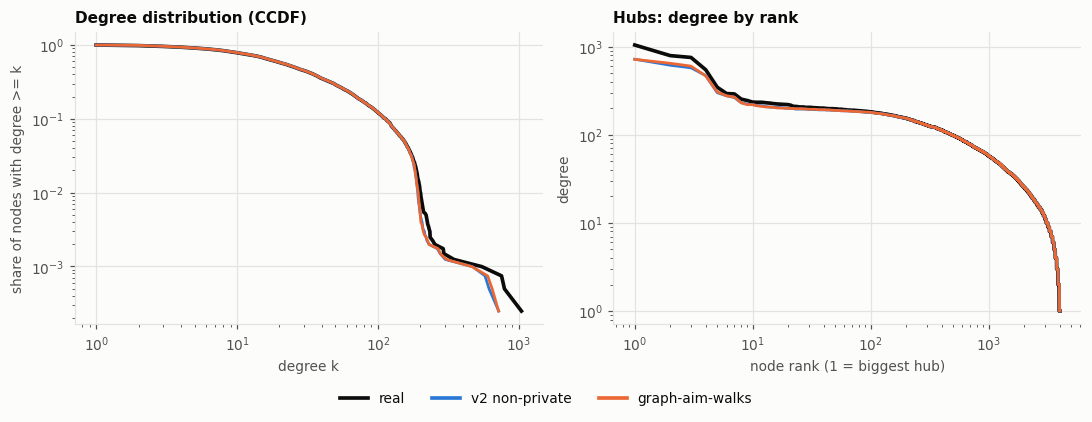

In [2]:
show(viz.degree_distribution(real, syns))

**What we see.** Identical to v2: every walks move is a degree-preserving swap, so the degree sequence is v2's (KS 0.007 against real). The hub tail is short in both (max degree 719 against 1,045), inherited from the v2 initializer.

## 2. Clustering: do friends of friends know each other?

Left: average local clustering of nodes with the same degree. Right: the spread of local clustering over all nodes.
*Look for:* the walks generator keeps `clustering_by_degree` in its energy; does it hold the level while it rewires?

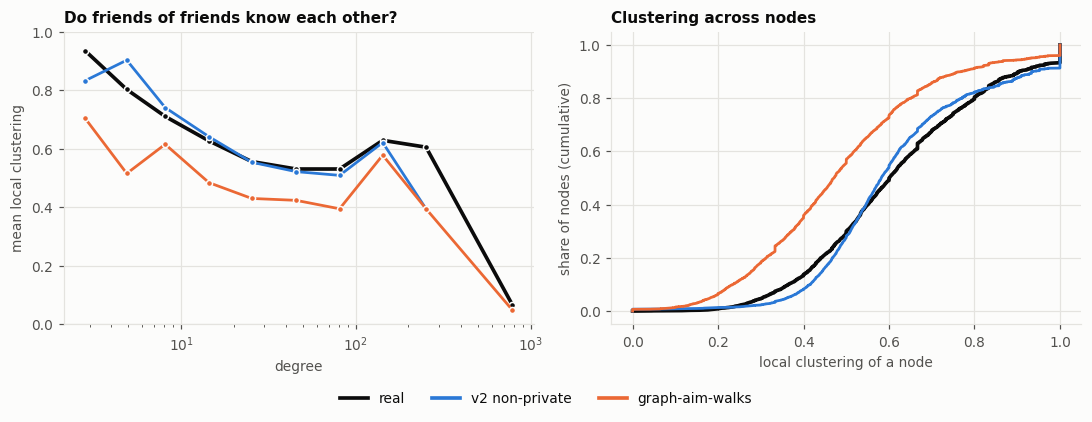

In [3]:
show(viz.clustering_by_degree(real, syns))

**What we see.** **The cost of this version.** Clustering falls well below the real curve at every degree: mean local clustering 0.39-0.70 instead of 0.53-0.93, and the per-node distribution (right) shifts left by about 0.15. The walk chain rewires edges that sat inside dense blocks to build longer-range regions, and the clustering term in its energy was not strong enough to stop it (W2 notes: clustering error 0.003 -> 0.122). This is the first thing to fix in the next iteration (a per-node clustering term or a hard band).

## 3. Who connects to whom, by degree

Each heatmap row is a degree class; the colours show where that class's friends sit (also by degree). The title gives
the assortativity coefficient. The curve below shows the average degree of a person's friends against their own
degree. *Look for:* the walks' `degree_lag` table is degree mixing at walk scale; does it move the pattern?

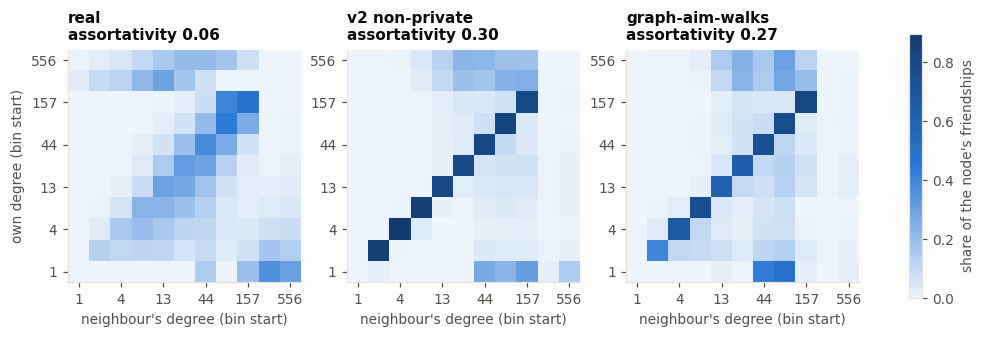

In [4]:
show(viz.degree_mixing(real, syns))

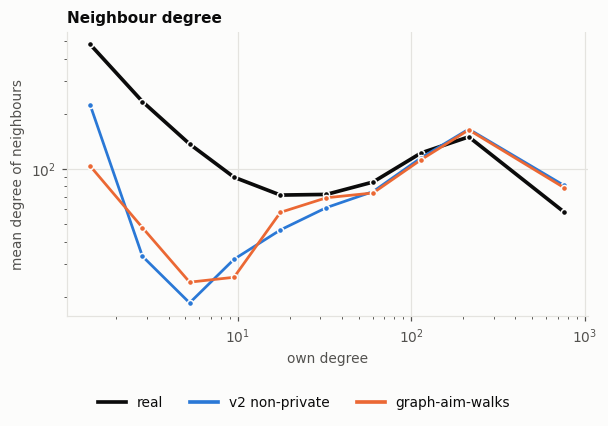

In [5]:
show(viz.neighbor_degree(real, syns))

**What we see.** Still too diagonal. v2's degree mixing is almost a staircase (assortativity 0.30, real 0.06); the walks chain loosens it a little (0.27) and the lowest-degree people now link more to mid-degree nodes, as in the real graph, but the real pattern of low-degree people attaching to hubs (bottom-right block) is still missing.

## 4. Distances and dense cores (held out)

Left: how many hops separate two random people. Right: how many nodes belong to a dense core. Neither is matched by
the walks generator (path lengths and k-cores are held out in the plan).

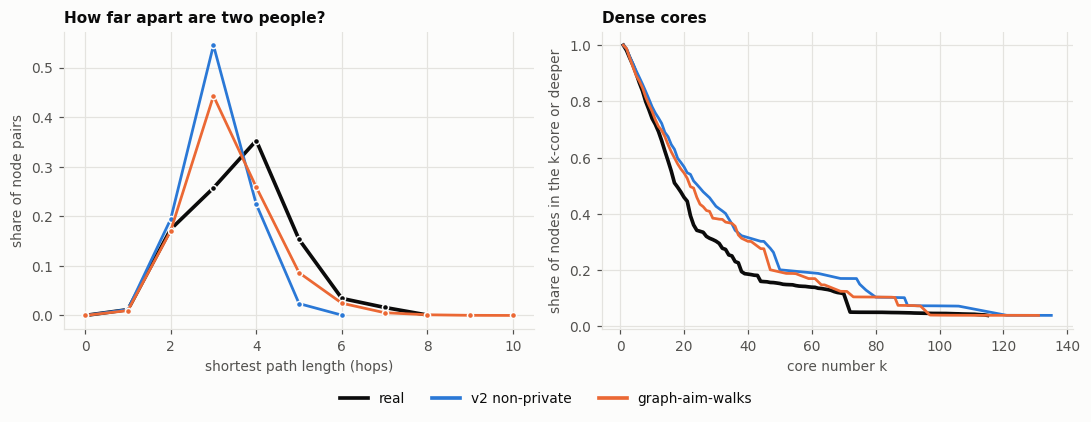

In [6]:
show(viz.paths_and_cores(real, syns))

**What we see.** The clearest structural win. Real distances peak at 4 hops; v2 peaks sharply at 3 (too compact). The walks graph moves most of the way back: the 3-hop peak drops from 55% to 44% of pairs and 4-6 hop distances fill in (path-length error 0.555 -> 0.275, held out: path length is not a matched statistic). Dense cores (right) are slightly closer to real too (degeneracy error 20 -> 11).

## 5. Attributes

**5a. How common is each value.** The bars compare the share of nodes per value; the walks generator's label moves
swap values between nodes, so these shares are those of its v2 start.

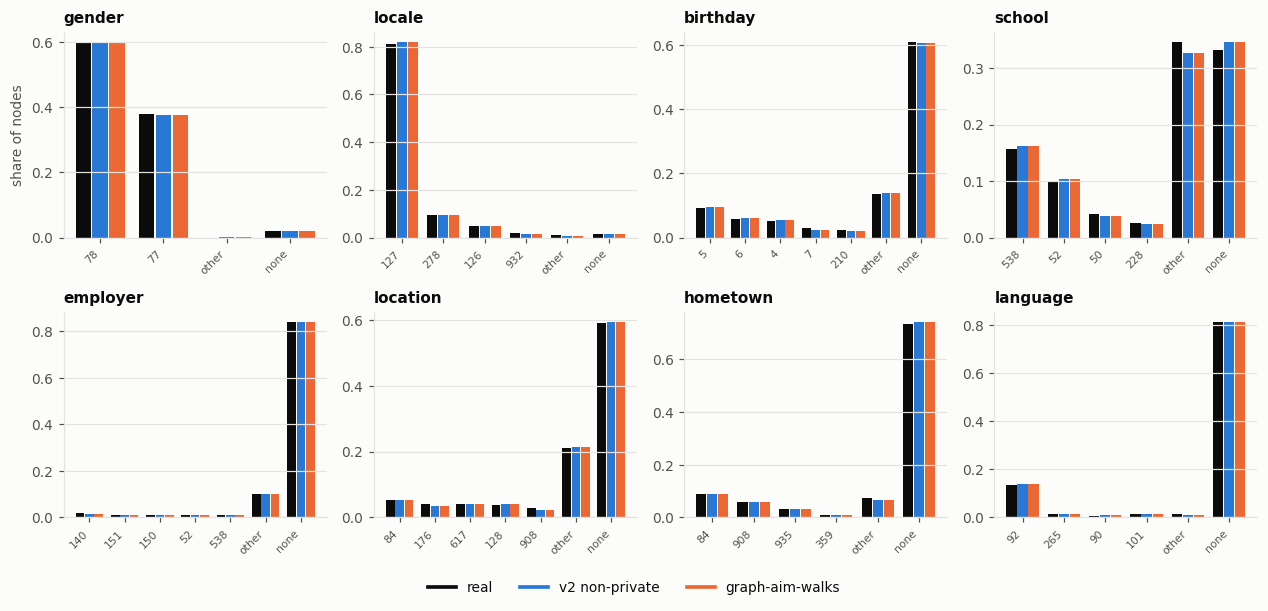

In [7]:
show(viz.attribute_marginals(real, syns))

**What we see.** Unchanged from v2 by construction: the label chain only swaps values between nodes, so every value's share is exactly preserved.

**5b. Do friends share attributes (homophily).** For people in a group of `ATTR` (rows), where do their friends
fall (columns)? Numbers are percent of friendships; a strong diagonal means friends tend to be in the same group.

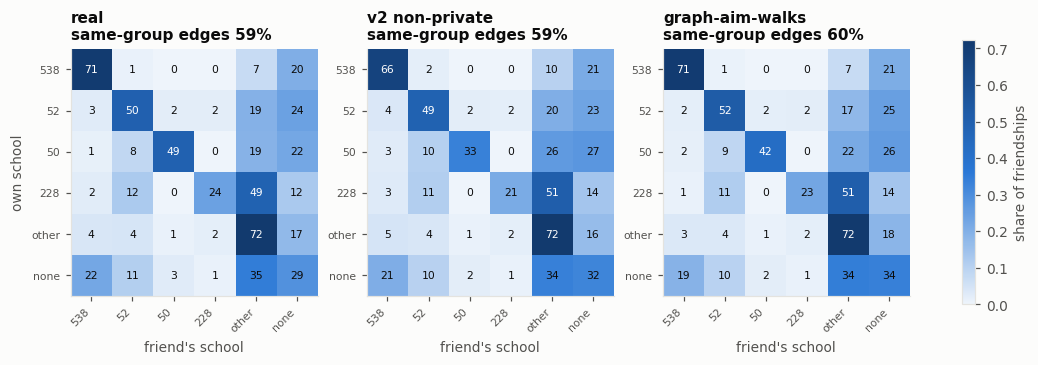

In [8]:
show(viz.homophily(real, syns, ATTR))

**What we see.** Matches the real school mixing very closely (60% same-group against 59%), and the per-row pattern (538 with 538 at 71%, 52 with 52 at 50-52%) is now within a few points everywhere. v2 already had the global rate; the walks chain also gets the smaller schools (school 50: 33% in v2, 42% here, 49% real).

**5c. Do attributes go together.** Cramer's V between each pair of node attributes in the real graph, in the
synthetic graph, and their difference (orange = synthetic more associated, blue = less).

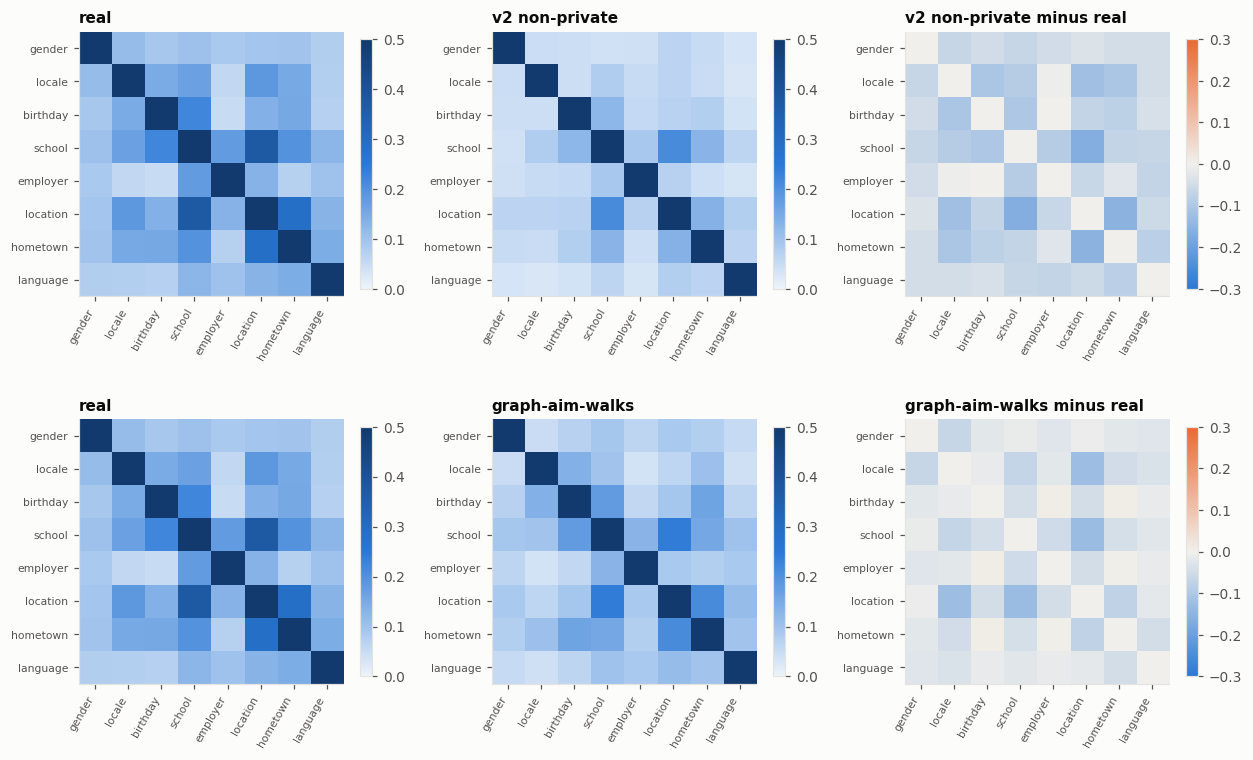

In [9]:
show(viz.attribute_association(real, syns))

**What we see.** Attribute pairs keep their association (2-way TVD 0.047 in v2, 0.033 here): the label chain holds the 2-way tables while it moves values.

## 6. Small examples

The same selection rule for every graph: the node whose degree is closest to the target, with median clustering
among those. Typical, not cherry-picked.

**6a. One person and their friends**, coloured by `ATTR`; columns are increasing degree.

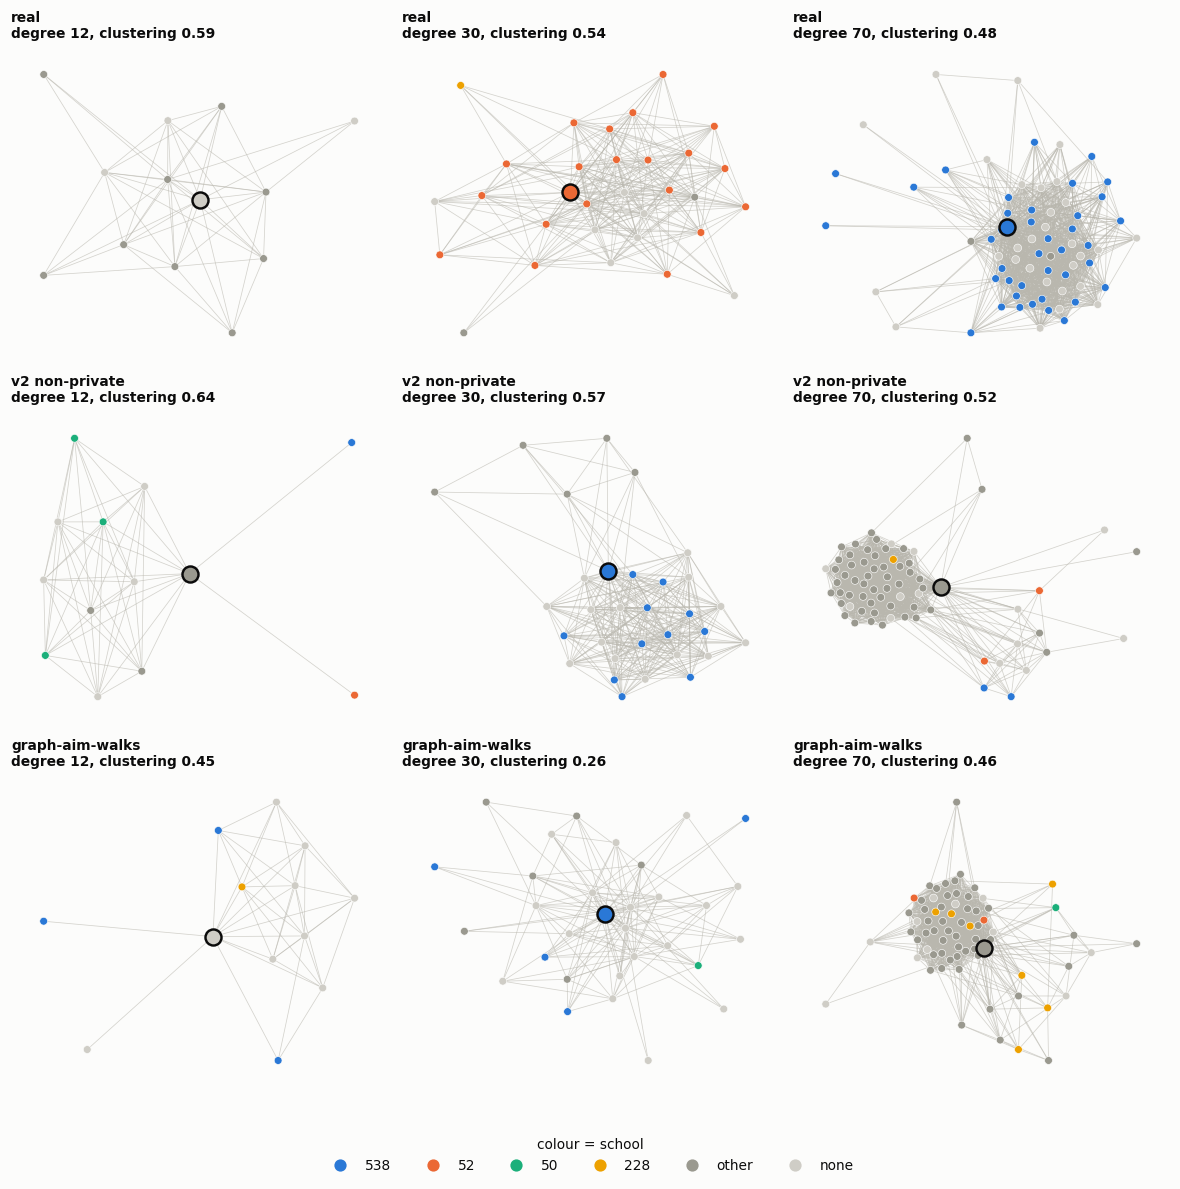

In [10]:
show(viz.ego_examples(real, syns, ATTR, targets=(12, 30, 70)))

**What we see.** Mixed. The degree-70 example now sits in a dense core like the real one, but the degree-30 example is sparse (clustering 0.26 against 0.54) - the clustering loss of section 2, seen on one person. Neighbourhood colours are about as mixed as in v2; the real degree-30 and degree-70 neighbourhoods are more single-coloured.

**6b. A connected patch of 60 nodes** found by walking outward from a typical node.

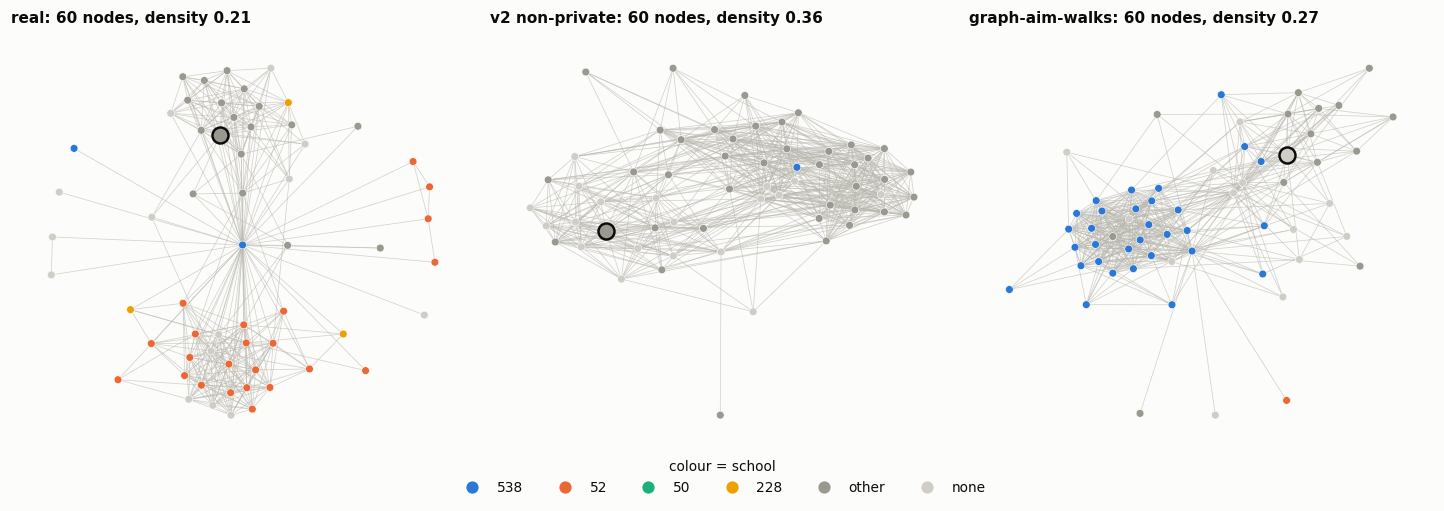

In [11]:
show(viz.bfs_sample(real, syns, ATTR, size=60, start_degree=20))

**What we see.** The walks patch has a dense single-school cluster (blue, school 538) attached to a looser mixed region, closer in shape to the real patch (two school-coloured communities joined through a hub) than v2's one uniform blob. Density 0.27 sits between v2 (0.36) and real (0.21).

## 8. Attribute coupling

Which kinds of people have many connections, and which kinds connect to each other (definitions in
`src/graph_aim/eval/coupling.py`). Mean degree per value, same-value lift per attribute against chance, and eta^2 of
log degree on each attribute.

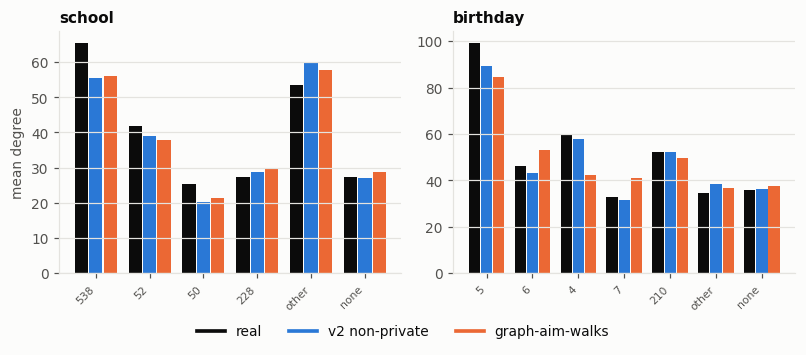

In [12]:
show(viz.degree_by_attribute(real, syns, ["school", "birthday"]))

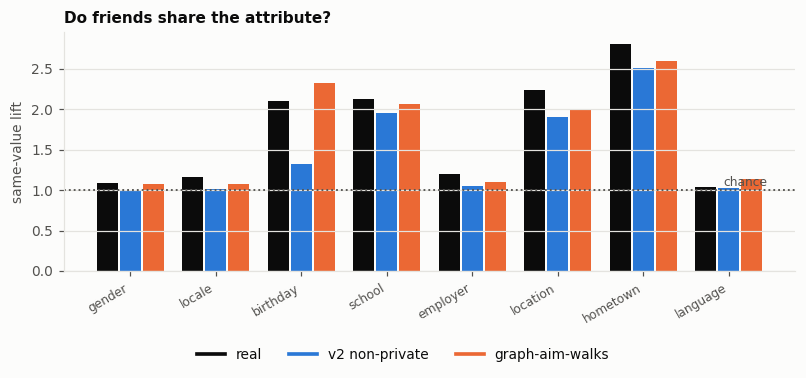

In [13]:
show(viz.homophily_lift(real, syns))

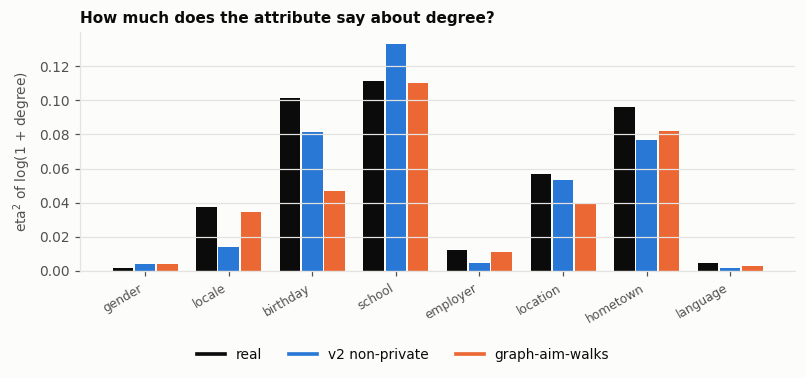

In [14]:
show(viz.degree_attribute_coupling(real, syns))

**What we see.** Unchanged from v2: degrees and attribute values are both preserved per stratum, so degree-by-attribute and eta^2 are v2's. Homophily lift moves toward real for every attribute v2 already steered, and overshoots birthday (2.3 against 2.1), which the walk tables steer only indirectly through its correlation with the others.

## 9. Communities (held out)

How the graph splits into groups of people who mostly know each other: Louvain (seed 0) and label propagation,
definitions in `src/graph_aim/eval/community.py` (those of `docs/snap/v2-diagnostic.md` section 1). (a) modularity;
(b) for every node, the size of its Louvain part; (c) for every node, the conductance of its part (0 = closed);
(d) the share of nodes in parts of at least 100 people, with the number of parts. The walks generator never sees a
partition. *Look for:* the real graph has a few large, closed parts (16 parts, node-weighted conductance 0.04); v2
reaches a similar modularity with many small, leaky ones. Does matching walks move the coloured curves toward black?

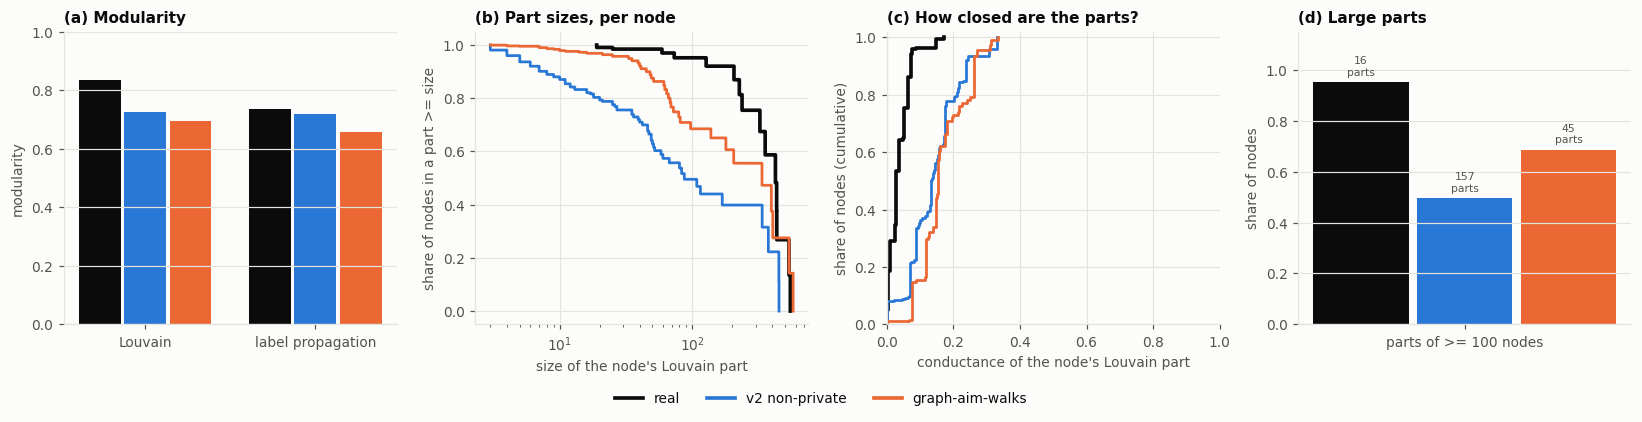

In [15]:
show(viz.community_structure(real, syns))

**What we see.** Communities are fewer and larger: Louvain finds 45 parts (v2: 157, real 16), a typical person's part has 335 nodes (v2 87, real 423) and 68% of people sit in parts of 100+ (v2 50%, real 95%). But they are **not more closed**: conductance stays at 0.14-0.17 (real 0.04) and modularity even dips (0.70 against v2's 0.73). The chain merged small blocks into bigger regions without sealing them; real communities leak 4x less. None of these statistics is matched by the generator, so this is a held-out check.

## 10. Walk statistics: matched and held out

One pool of 50,000 random walks of 128 steps per graph, with the contract's walk process
(`src/graph_aim_walks/transfer/walkstats.py`); statistics in `src/graph_aim_walks/eval/metrics.py`. The grey band is
held out: the generator matched walks of 32 steps (return, coverage, attribute agreement at lags up to 16, share
distributions in windows of 8 / 16 / 32 steps), never steps beyond 32, lags beyond 16, or windows of 64 and 128.
Hollow markers are held-out points.

- Row 1: probability that a walk is back where it started after *t* steps (dense regions trap walks); distinct nodes
  visited (how fast walks escape); the top 16 eigenvalues of the walk matrix (eigenvalues near 1 = near-separate
  regions); the across-walk variance of a value's share among the nodes a walk visits (high = walks stay in regions
  where one value dominates), averaged over school, hometown and location.
- Row 2: probability that the node *k* steps later is in the same group, per group.
- Row 3: the share variance per attribute.

*Look for:* how close the walks generator is on the matched part (it was fitted there), and above all whether the
held-out windows 64 and 128 follow: a generator that only learned the tables would fall away from black beyond the
band's edge.

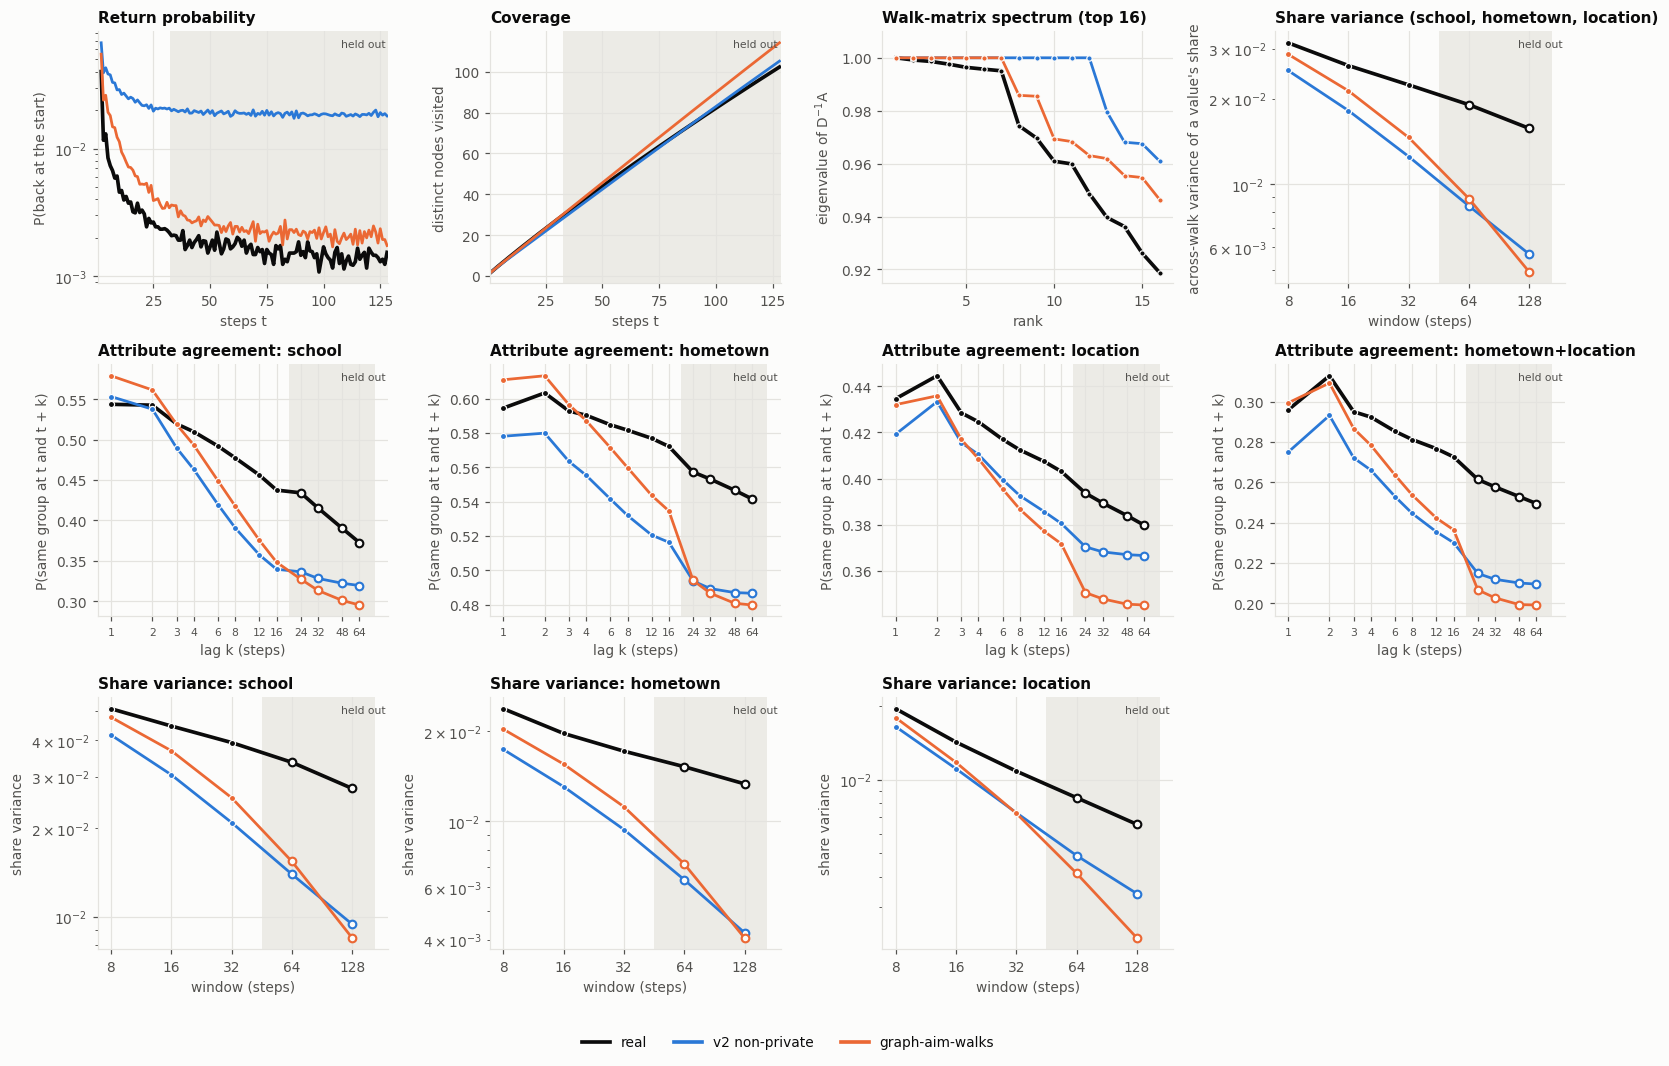

In [16]:
SPEC = default_spec(real)
profiles = {"real": walk_profile(real, SPEC, n_walks=50000, seed=0)}
profiles.update({label: walk_profile(g, SPEC, n_walks=50000, seed=0) for label, g in syns.items()})
show(walks_viz.walk_profiles(real, syns, spec=SPEC, profiles=profiles))

**What we see.** Matched part (white background): return probability, coverage and the attribute-agreement curves up to lag 16 move a long way toward real - return probability from 10x too high to about 1.5x, and the agreement curves sit near the real ones for school, hometown and location at short lags. Held-out part (grey): beyond 16-32 steps the walks curves fall away exactly like v2's. Agreement at lag 24-64 drops to v2's level or below, and the share variance at windows 64 and 128 is 0.47 and 0.31 of real (v2: 0.44 and 0.36). The spectrum shows the same thing: the walks graph has 7 eigenvalues near 1 like the real graph, but the next ones (ranks 8-16) stay higher than real. So the chain reproduces composition and trapping at the scale it was fitted on and not beyond: real regions stay coherent over 100+ steps, synthetic ones do not.

## 11. The numbers

Distances to the real graph (0 = identical on that statistic), the community scalars of every graph, and the
walk-statistic gaps (`wlk_*`; share-variance ratio syn / real, 1 = real, per window with 64 and 128 held out). The
multi-seed versions are the `com_*` and `wlk_*` columns of `snap/eval/results_walks/sweep.csv` once scored.

In [17]:
comparison_table(real, syns, homophily_attrs=[ATTR]).round(3)

,v2 non-private,graph-aim-walks
degree_ks,0.007,0.007
degree_emd,0.577,0.543
clustering_abs,0.003,0.122
clustering_rel,0.006,0.202
transitivity_abs,0.000,0.056
transitivity_rel,0.000,0.108
triangles_abs,131965.000,287166.000
triangles_rel,0.082,0.178
path_length_abs,0.578,0.288
path_length_rel,0.159,0.079


In [18]:
pd.DataFrame({label: community_metrics(g) for label, g in {"real": real, **syns}.items()}).round(4)

,real,v2 non-private,graph-aim-walks
modularity_louvain,0.8349,0.7261,0.6954
modularity_lpa,0.7369,0.7184,0.6588
n_parts,16.0000,157.0000,45.0000
nodes_in_large_parts_share,0.9517,0.4952,0.6848
nw_median_part_size,423.0000,87.0000,335.0000
nw_conductance,0.0382,0.1414,0.1671
n_parts_lpa,44.0000,242.0000,198.0000
lpa_nodes_in_large_parts_share,0.8948,0.1958,0.3875
spectral_gap,0.0008,0.0000,-0.0000


In [19]:
pd.DataFrame({label: walk_metrics(real, g, real_profile=profiles["real"], syn_profile=profiles[label])
              for label, g in syns.items()}).round(4)

,v2 non-private,graph-aim-walks
wlk_return_abs,0.0211,0.0045
wlk_return_abs_heldout,0.0172,0.0007
wlk_coverage_abs,0.9136,0.1426
wlk_coverage_abs_heldout,1.1988,5.4268
wlk_attr_lag_tvd_school,0.1270,0.0903
wlk_attr_lag_tvd_hometown,0.0902,0.0662
wlk_attr_lag_tvd_location,0.0795,0.0601
wlk_attr_lag_tvd_hometown+location,0.2789,0.1754
wlk_attr_lag_tvd_mean,0.1439,0.0980
wlk_attr_same_abs_heldout,0.0498,0.0627


**What we see.** In numbers. Against v2 non-private: walk return error 0.021 -> 0.004, coverage error 0.91 -> 0.14, attribute-lag TVD 0.144 -> 0.085, path-length error 0.58 -> 0.29, 45 Louvain parts instead of 157. Held-out coverage beyond 32 steps gets worse (error 1.2 -> 5.4 nodes: walks escape too fast once they leave a region), held-out share variance does not improve, and clustering (0.003 -> 0.122) and triangles (0.08 -> 0.18) get clearly worse.

## 12. Small walks only (up to 32 steps)

The generator was fitted on walk statistics of at most 32 steps, and the discriminator now also looks only at samples of 10-32 nodes (`viz_discriminator_walks.ipynb` section 5). This section repeats the walk statistics at that scale only - 32-step walks, lags up to 16, windows 8 / 16 / 32, nothing held out - and shows a 32-node patch instead of a 60-node one.

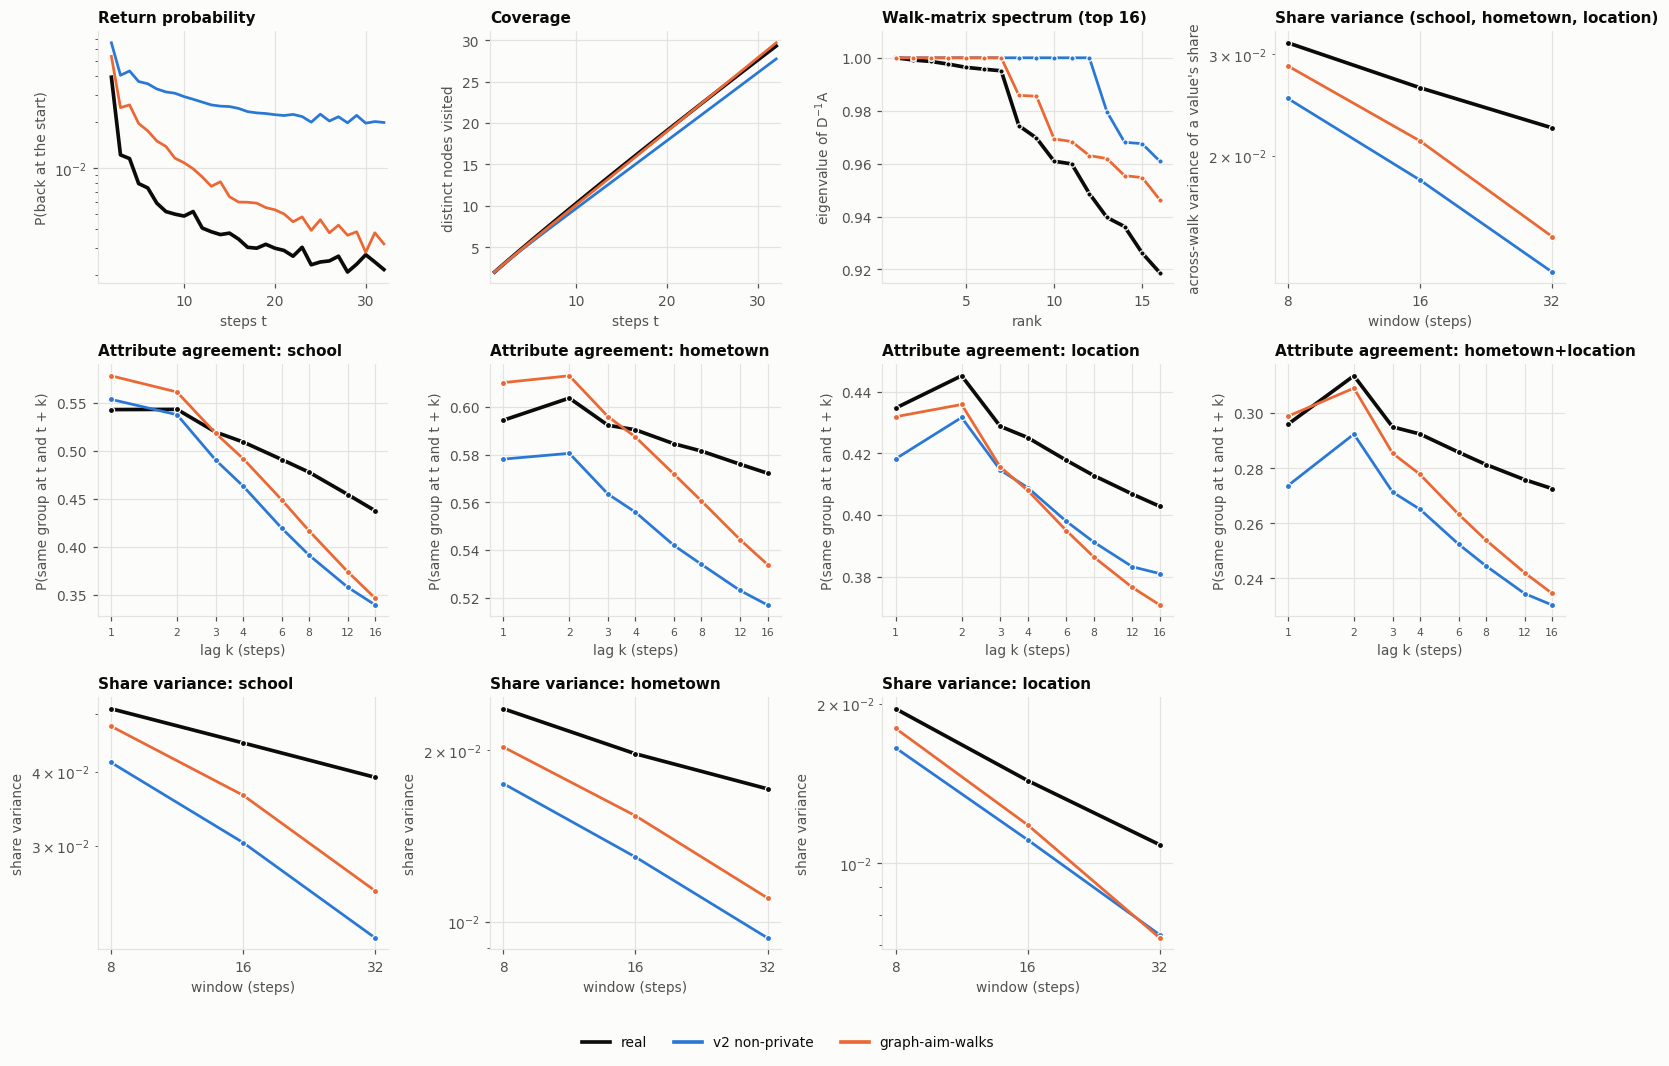

In [20]:
SMALL = dict(length=32, held_out_windows=(), held_out_lags=())
small_profiles = {"real": walk_profile(real, SPEC, n_walks=50000, seed=0, **SMALL)}
small_profiles.update({label: walk_profile(g, SPEC, n_walks=50000, seed=0, **SMALL) for label, g in syns.items()})
show(walks_viz.walk_profiles(real, syns, spec=SPEC, profiles=small_profiles))

In [21]:
small_metrics = pd.DataFrame({label: walk_metrics(real, g, spec=SPEC, real_profile=small_profiles["real"],
                                                   syn_profile=small_profiles[label]) for label, g in syns.items()})
small_metrics[~small_metrics.index.str.contains("heldout|w64|w128")].round(4)

,v2 non-private,graph-aim-walks
wlk_return_abs,0.0213,0.0045
wlk_coverage_abs,0.9315,0.1397
wlk_attr_lag_tvd_school,0.1267,0.0911
wlk_attr_lag_tvd_hometown,0.0908,0.0672
wlk_attr_lag_tvd_location,0.0790,0.0599
wlk_attr_lag_tvd_hometown+location,0.2801,0.1766
wlk_attr_lag_tvd_mean,0.1441,0.0987
wlk_share_var_ratio_w8,0.8003,0.9117
wlk_share_var_ratio_school_w8,0.8120,0.9345
wlk_share_var_ratio_hometown_w8,0.7390,0.8568


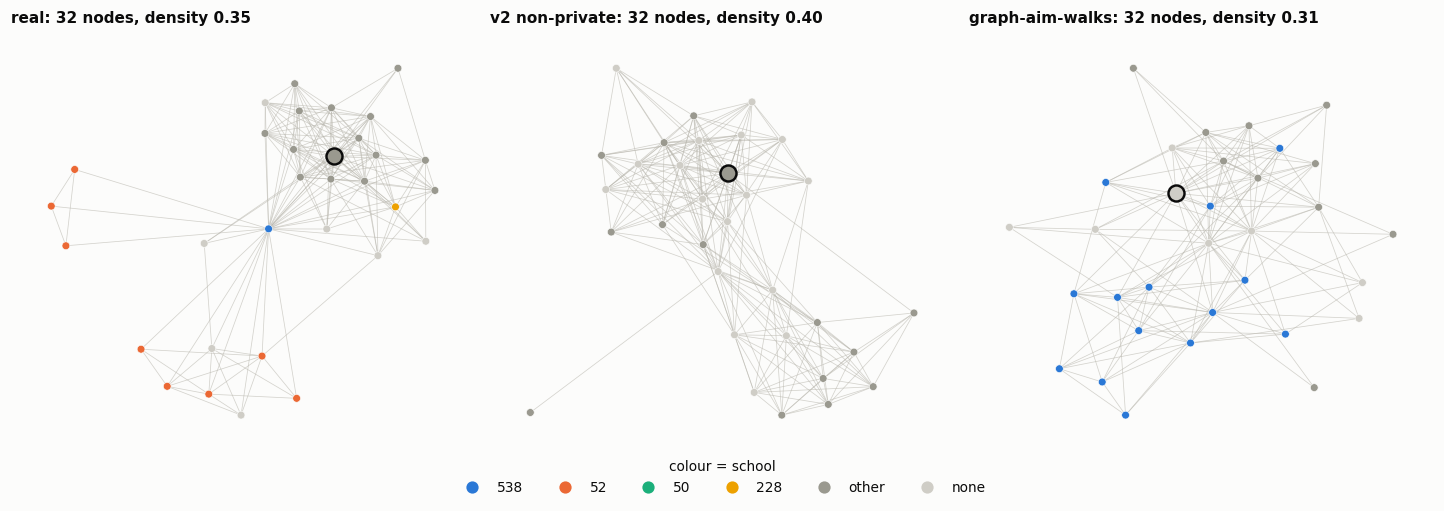

In [22]:
show(viz.bfs_sample(real, syns, ATTR, size=32, start_degree=20))

**What we see.** Within the fitted scale the walks graph is closer to real than v2 on every walk statistic, but it does not match it. Return probability: v2 is about 10x the real value at every step, the walks graph about 1.5x (error 0.021 -> 0.004); coverage is now on the real line (error 0.93 -> 0.14 nodes). Attribute agreement starts right (lags 1-3, even slightly above real for school and hometown) but **decays faster than real with distance**: by lag 16 school agreement is 0.35 against 0.44, hometown 0.53 against 0.57. The same shows in the share variance: 0.91 of real in 8-step windows, 0.81 at 16 and 0.65 at 32 (v2: 0.80 / 0.69 / 0.56). So even at the scale it was fitted on, regions are coherent over a few steps and then dissolve faster than real ones - consistent with the leaky communities of section 9 and with the remaining discriminator signal at 10-32 nodes (gbm 0.983). The 32-node patch shows the same: real is a dense core plus a separate school-52 group hanging off one connector, v2 is two blobs, the walks graph is one looser region with a school-538 cluster inside it.

## Caveats

- One synthetic graph per method (seed 0); the score sweep has the seed spread.
- Both synthetic series are **non-private**: their artifacts hold exact statistics of the real graph. They answer a
  fidelity question (can this generator class reach real-looking walks?), not a privacy one.
- The walk statistics of section 10 come from one pool of 50,000 walks per graph (seed 0): they carry sampling
  error, so small differences between curves are not findings.
- These plots compare distributions, not individual nodes: synthetic nodes are not matched to real ones.